# Unit 3 · Exercise 1: Covariance and Pearson correlation

Executed learning workbook, prepared 5 November 2026. Adapted from the supplied University of Essex Online notebook. The original examples appear first, followed by controlled experiments and interpretation.

**How to use:** Run all cells from top to bottom. Find **Change these values**, change one setting, then run all again. Keep the random seed fixed when comparing a change in noise or model settings. Read the printed results alongside the plots; outputs describe these teaching datasets only.

**Corrections and provenance:** Original seed, sample size and data-generating equations are retained. The unused seaborn import is removed. Covariance uses the sample denominator (n − 1); the original printed standard deviations use the population denominator (n).

The supplied activity specifies running and varying four programs; it does not specify an essay word count or a separate submission format. These notebooks provide execution evidence and observations. Review and personalise the final reflection prompts yourself.

## 1. Original example (corrected where needed)

**Execution note:** All code cells were executed in order in a fresh local IPython session, with actual printed results and figures captured below. This environment does not permit the socket-based Jupyter kernel launcher. Rerun in your own Jupyter or Colab session for your course workflow.

data1: mean=100.776 stdv=19.620
data2: mean=151.050 stdv=22.358
Covariance: 389.755
Pearsons correlation: 0.888


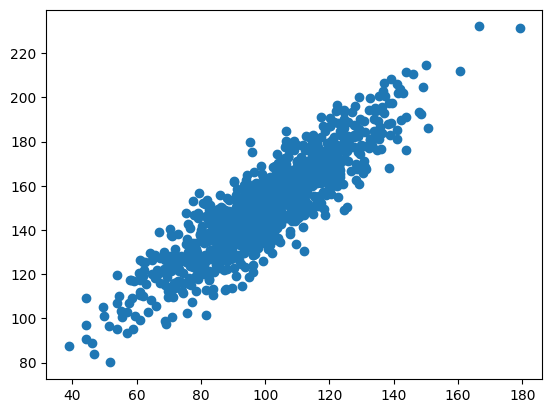

In [1]:

# calculate the Pearson's correlation between two variables
from numpy import mean
from numpy import std
from numpy import cov
from numpy.random import randn
from numpy.random import seed
from matplotlib import pyplot as plt


from scipy.stats import pearsonr
# seed random number generator
seed(1)

# prepare data
data1 = 20 * randn(1000) + 100
data2 = data1 + (10 * randn(1000) + 50)

# calculate covariance matrix
covariance = cov(data1, data2)

# calculate Pearson's correlation
corr, _ = pearsonr(data1, data2)

# plot
plt.scatter(data1, data2)
plt.show()

# summarize
print('data1: mean=%.3f stdv=%.3f' % (mean(data1), std(data1)))
print('data2: mean=%.3f stdv=%.3f' % (mean(data2), std(data2)))
print('Covariance: %.3f' % covariance[0][1])
print('Pearsons correlation: %.3f' % corr)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import r2_score, mean_squared_error
from IPython.display import display
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.2, 'font.size': 10})

## 2. Controlled experiments
We reuse the same random draws so changing noise is not confounded by a new sample. The negative relationship and nonlinear example are explicitly synthetic demonstrations.

Noise change: r 0.888 → 0.374


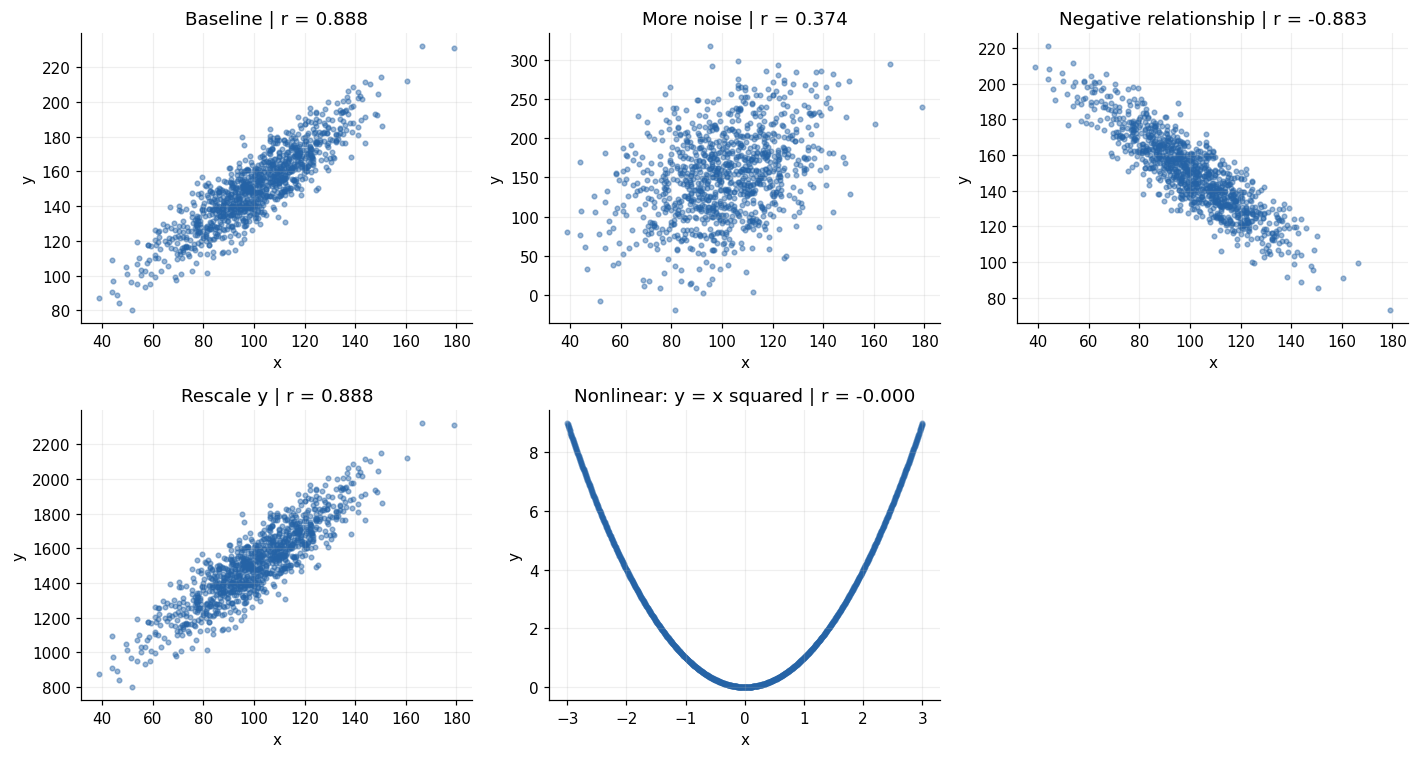

,Scenario,n,Sample covariance,Pearson r
0,Baseline,1000,389.7546,0.8876
1,More noise,1000,407.4409,0.3737
2,Negative relationship,1000,-380.9114,-0.8832
3,Rescale y,1000,3897.5456,0.8876
4,Nonlinear: y = x squared,1000,-0.0000,-0.0000


In [3]:
# Change these values, then run all cells again.
SAMPLE_SIZE = 1000
HIGH_NOISE_SD = 50
Y_SCALE = 10
RANDOM_SEED = 1
assert SAMPLE_SIZE >= 3 and HIGH_NOISE_SD >= 0 and Y_SCALE > 0
rng = np.random.RandomState(RANDOM_SEED)
a = 20 * rng.randn(SAMPLE_SIZE) + 100
noise = rng.randn(SAMPLE_SIZE)
b = a + 10 * noise + 50
u = np.linspace(-3, 3, SAMPLE_SIZE)
scenarios = {
    'Baseline': (a, b),
    'More noise': (a, a + HIGH_NOISE_SD * noise + 50),
    'Negative relationship': (a, -a + 10 * noise + 250),
    'Rescale y': (a, Y_SCALE * b),
    'Nonlinear: y = x squared': (u, u**2),
}
rows=[]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (name, (xx, yy)) in zip(axes.flat, scenarios.items()):
    rr=stats.pearsonr(xx, yy).statistic
    cv=np.cov(xx, yy, ddof=1)[0, 1]
    rows.append({'Scenario':name, 'n':len(xx), 'Sample covariance':cv, 'Pearson r':rr})
    ax.scatter(xx, yy, s=9, alpha=0.45, color='#2563a6')
    ax.set(title=f'{name} | r = {rr:.3f}', xlabel='x', ylabel='y')
axes.flat[-1].axis('off')
fig.tight_layout(); plt.show()
correlation_results = pd.DataFrame(rows)
display(correlation_results.round(4))
print(f"Noise change: r {correlation_results.iloc[0]['Pearson r']:.3f} → {correlation_results.iloc[1]['Pearson r']:.3f}")

## 3. Interpretation

Increasing independent noise weakens the linear relationship in this controlled run. Reversing the signal changes the sign of correlation. Multiplying y by a positive constant changes covariance in proportion to the units, while Pearson r stays the same. The symmetric squared relationship has essentially zero Pearson r even though y is completely determined by x: zero linear correlation does not mean no relationship.

**Try next:** Set HIGH_NOISE_SD to 20 and then 100; change Y_SCALE to 100. For a sample-size experiment, change SAMPLE_SIZE to 30, but recognise that this creates different samples rather than a strict paired comparison. Correlation alone never proves causation.

## Professional interpretation and personal reflection

- **Dataset suitability:** These are synthetic or small teaching datasets. A strong fit does not establish representativeness, causation or fitness for operational use.
- **Ethical and social issues:** Do not remove inconvenient outliers to improve a score. Investigate whether they are errors or valid cases; rare cases can matter disproportionately in real decisions. Report uncertainty and subgroup limitations.
- **Legal and professional issues:** Before using real personal data, establish the applicable permission or lawful basis, privacy safeguards and data-use terms. These examples do not demonstrate legal compliance. Preserve provenance, units, changes and reproducible execution evidence.
- **Your reflection:** Which change did you rerun? What did you expect, what actually changed, and what would you check before using the model for a real decision? Write your own answers after inspecting the results.

## References
University of Essex Online (2026) *Unit03 Ex1 covariance_pearson_correlation* [teaching notebook supplied with the activity].

SciPy developers (n.d.) *pearsonr*. Available at: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html (Accessed: 5 November 2026).